<a href="https://colab.research.google.com/github/catzmat/DATA201-labs/blob/main/Assignments/Catherine_Matenje_Week_9_HW_11_12_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Catherine Matenje

DATA 201

Week 9 Assignment

November 13, 2026

**Dataset:** ISLP Carseats

The data set contains information about carseat sales at 400 stores including product prices, advertising budgets, store locations and sales.

**Goal of the assignment:**

Build and evaluate a decision tree, then explore how tree depth affects overfitting.

We want to predict whether a store has High Sales or Low Sales

Understanding and Exploring the Dataset

In [2]:
# Installing ISLP
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# Importing Packages and loading the Data Set from ISLP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
carseats = load_data('Carseats')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV # from sk skirt learn
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [4]:
# Exploring/inpecting the Data set and checking missing values

carseats.head()

print('Original shape:', carseats.shape)
display(carseats.head())
print('Missing values:')
print(carseats.isna().sum().sort_values()) # summing all missing values in data set, sorting from lowest to highest

# There are 400 rows representing differents stores and 11 columns representing different characteristics of sales at each store
# There are no missing values

Original shape: (400, 11)


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


Missing values:
Sales          0
CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
dtype: int64


**Part I: Build a Classification Tree**

In [5]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [6]:
# Encoding Categorical Predictors in Text Format: Shelvloc, Urban and US
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc', 'Urban', 'US']).astype(int) #removing the target variable, making all the Xs all the features and remvoing target
y = carseats['HighSales']

# Splitting Data into 70% training and 30% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print (X_train.shape, X_test.shape)

X_train.head() # checking first 5 observations of the training predictors

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
69,127,59,0,339,99,65,12,0,0,1,0,1,1,0
273,116,106,8,244,86,58,12,0,0,1,0,1,0,1
226,119,33,0,245,122,56,14,0,1,0,0,1,1,0
305,115,29,26,394,132,33,13,0,0,1,0,1,0,1
92,114,113,0,97,125,29,12,0,0,1,0,1,1,0


In [7]:
X_test.head() # checking first 5 observations of the testing predictors

,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
85,125,103,0,304,112,49,13,0,0,1,1,0,1,0
44,85,79,6,325,95,69,13,0,0,1,0,1,0,1
160,111,28,0,486,111,29,12,0,0,1,1,0,1,0
93,145,30,0,67,104,55,17,0,0,1,0,1,1,0
177,138,72,0,148,94,27,17,0,0,1,0,1,0,1


In [8]:
print (y_train.shape, y_test.shape)

(280,) (120,)


In [9]:
y_train.head() # checking the first 5 observations in the training target

,HighSales
69,0
273,1
226,0
305,1
92,0


In [10]:
y_test.head() # checking the first 5 observations in the testing target

,HighSales
85,1
44,0
160,0
93,1
177,1


In [11]:
# Training a DecisionTreeClassifier with max_depth=3

tree1 = DecisionTreeClassifier(max_depth=3, random_state=21)
tree1.fit(X_train, y_train) #fitting the training data



DecisionTreeClassifier(max_depth=3, random_state=21)

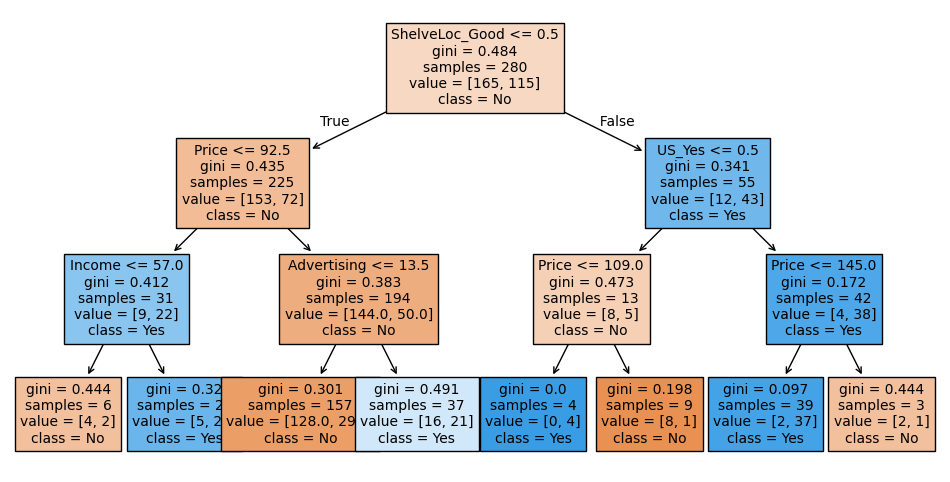

Train accuracy: 0.8
Test accuracy:  0.8


In [12]:
# Plotting the tree and reporting training and test accuracy
plt.figure(figsize=(12, 6))

plot_tree(tree1,
          feature_names=list(X.columns), # x columns - the features names/predictors
          class_names=['No', 'Yes'], # Here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, # Colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree1.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree1.score(X_test, y_test), 3))


**Part II: Investigate Overfitting**

In [13]:
# Training decision tree with max_depth values from 1 to 10
depths = range(1, 11)

In [20]:
# Using GridsearchCV with 5-fold cross-validation on the training data
# to calculate mean accuracy at different depths for the decision trees

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=21), # maintaining the same random state as in part 1
    param_grid={'max_depth': depths}, # checking depths 1 to 10 as indicated above
    cv=5, # ensuring 5-fold cross validation
    scoring='accuracy'
)

# Fiting the model using the training data
grid.fit(X_train, y_train)

# Calculating and printing the mean cross-validation accuracy for each depth
print('Tree depths:', grid.cv_results_['param_max_depth'])
print('Mean CV accuracy:', grid.cv_results_['mean_test_score'].round(3)) # calculaing the mean validation accuracy scores

# Creating a simple table to better view the tree depths and correpsodning mean CV accuracy scores
cv_table = pd.DataFrame({
    'Tree Depth': grid.cv_results_['param_max_depth'],
    'Mean CV Accuracy': grid.cv_results_['mean_test_score']
})

# Printing table with scores rounded to the 3rd decimal
print(cv_table.round(3))


Tree depths: [1 2 3 4 5 6 7 8 9 10]
Mean CV accuracy: [0.668 0.682 0.718 0.736 0.7   0.743 0.721 0.721 0.711 0.714]
   Tree Depth  Mean CV Accuracy
0           1             0.668
1           2             0.682
2           3             0.718
3           4             0.736
4           5             0.700
5           6             0.743
6           7             0.721
7           8             0.721
8           9             0.711
9          10             0.714


The mean CV accuracy increases steadily from depths 1–4, decreases at depth 5, and then increases to its highest value of 74.3% at depth 6. After depth 6, accuracy generally decreases with some fluctuations.

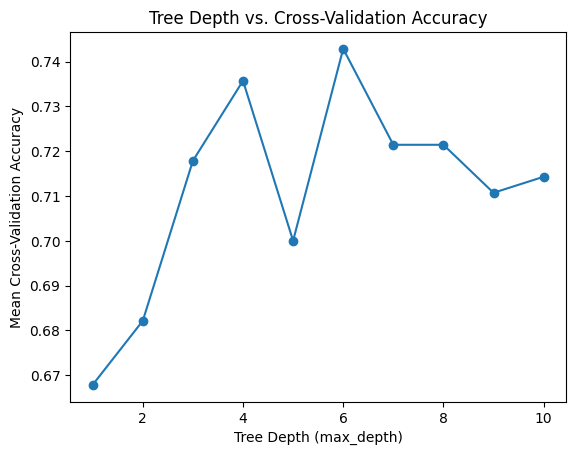

In [15]:
# Creating a graph showing Tree Deph vs Cross-validation Accuracy

# First, retrieving the depths and corresponding mean Cv accuracy scores printed above
depths = grid.cv_results_['param_max_depth']
cv_acc = grid.cv_results_['mean_test_score']

# Graphing the tree depth vs mean cross-validation accuracy
plt.plot(depths, cv_acc, marker='o')

plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('Tree Depth vs. Cross-Validation Accuracy')

plt.show()


The graph confirms the results from earlier that the best mean cv accuracy score appears to be a t depth 6 (74.3%)

In [16]:
# Identifying the best depth based on cross-validation

# The best depth is the one that has the highest mean CV acuracy score

print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3)) # Printing the highest mean Cv score


Best settings: {'max_depth': 6}
Best CV accuracy: 0.743


In [17]:
# Training a final tree using the best depth idenitfied above and evaluating on test set

# The grid.fit in the gridsearchCv code already fit a final tree using the best depth on the training data
# but I will retrieve the final tree that has already been fitted


# Best depth selected by GridSearchCV
final_tree_best_depth = grid.best_estimator_

# Evaluate final tree performance on the training and test data
print('Final training accuracy:', round(final_tree_best_depth.score(X_train, y_train), 3))
print('Final test accuracy:', round(final_tree_best_depth.score(X_test, y_test), 3))


Final training accuracy: 0.911
Final test accuracy: 0.767


**Part II: Answer the Following Questions**

**1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?**

ShelveLoc_Good <=0.5 was selected for the first split aka the root. It was originally a categorical (text) predictor but after encoding, it was converted to numerical indicator variables ShelveLoc_Good, ShelveLoc_Bad, ShelveLoc_Medium. I'm assuming this variable has to do with Sshelve locations in the stores and whether the shelve locations are good, bad, or in between in terms of the sales. So looking at the first split, it separates stores with ShelveLoc_Good true(left) meaning not good shelve locations (because 0 is less than or equal to 0.5) which can include Bad or Medium Shelve Locations, from stores with ShelveLoc_Good false (right) meaning  good shelve locations (because 1 is greater than 0.5 )

Overall, the fact that ShelveLoc_Good is the root split tells us that shelve location is important when predicting if a store has low or high sales.


**2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?**

According to my corss-validation graph, a tree depth of 6 peformed the best with a mean CV accuracy of 74.3%. We should use cross-validation over test accuracy to choose the best tree depth because cross validation allows us to compare different depths using the training data alone.

We should never use the test data for cross-validation because then we are introducing data leakage which can affect your interpretation. Our goal is always to evaluate how well the final model performs on new observations. The test data always represents new observations therefore we do not use it to make model decisions. We use the training data for that specific reason.

**3. Overfitting: Does increasing tree depth always improve cross-validation accuracy? Explain using your graph.**

No, inreasing tree dephth does not always imporve CV accuracy. As you can see from my graph above, the mean CV accurancy seems to increase steadily between depths 1-4, it decreases at depth 5, then increases again to the highest at depth 6 (74.3%), and then drops again with some fluctuations here and there after that.

This shows that a more complex tree does not always mean better performance. This is likely because increasing tree depth means the model is becoming more flexible and possibly picking up random noise rather than important or useful patterns in the training data. This can increase the chances of overfitting.

**Wrap-Up Questions from Decision Tree Lab**


**1. What does a leaf predict in a classification tree? In a regression tree?**

In a classification tree, the leaf predicts the most common class, meaning the class that has the most observations, in that leaf. For example, in the Week 9 lab, we used a classification tree to predict whether a patient had heart disease (yes/no). In a regression tree, the leaf predicts the mean of responses in that leaf. For example, in the Week 9 lab, we used the Hitters data set to predict baseball players' salaries. Each split or branch determine which observations, in this case patients or baseball players, reach each leaf.


**2. Why did the full tree reach 100% training accuracy but do worse on the test set?**

The full tree reaches 100% training accuracy but did worse on test set because the tree was not restricted. It was allowed to grow and continue growing and splitting which made it very complex. The more complex a tree becomes, the more likely it is to overfit. This means that while it's goal is to split the observtions into smaller and smaller groups, some patterns that are learned might be random noise in the training set. So when we attempt to evaluae the model on new observations in the the test set, it may perform worse because some of the patterns learned during training do not generalize well enough.

**3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?**


Two ways to limit tree complexiity are pre-pruning and post-pruning. Pre-pruning allows us to limit how complex or large our tree can become by setting maximu values for depth, leaves or by setting a minimum number of observations that can reach a leaf at each plit. Post-pruning on the other hand allows the tree to become as complex as possible, then we remove branches using a measure such as cc_alpha as we did in the lab.

In the lab, cross-validation helps us tune both pre-pruning using max_depth, and min_samples_leaf and post-pruning using ccp_alpa.

**4. Why do we not need to scale features before fitting a tree?**


We do not need to scale features before fitting a decision tree because trees split or make predictions based on the actual values of each feature rather than distances between observations. This is different from KNN from week 8 where scaling was crucial because KNN makes predictions based on K nearest neighbors or the majority vote of the neighbors surrounding each observation.

In decision trees, each prediction is made by splitting the observations based on the values or specific thresholds of a feature or predictor. For example, in week 9 lab, the decision tree used Age <=55.5 yrs as a threshold. If we were to decide to change the unit for Age to months, the tree would still be able to split the observations into groups even if the threshold would change. We would not need to scale before fitting.  

**5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)**


This would be incorrect because a feature can have an importance score of and still be relevant to the outcome in this case heart disease. My understanding is the feature importance score is how much a feature or predictor contributes to reducing impurity in the decision tree splits. Also, impurity is how mixed the outcome or target variable classes are within each leaf or note such as patients with (yes) or without(no) heart disease.

If Age is given an importance score of 0, it simply means Age did not contribute to reducing impurity through the splits in that specific tree or branch. But it is still possible that age is useful overall.

This sort of reminds me of week 8 hwk, where just because a predictor was eliminated by LASSO, it did not mean it was useless.

**6. Name one strength and one weakness of a single decision tree that you saw in this lab.**

One strength of a single decison tree is that they give us a visual snapshot of the model and are pretty easy to understand by following the splits/branches/leaves. One weakness is that they can overfit on training data if they become to complex. This is why it is important to determine the best depth using cross validation or alternatively, use methods such as pre-pruning to manage complexity.